# Medido frente a modelado en los diez muestreos: el filtro de expectativas, los residuos de tonelaje y la potencia que no sigue

**Pregunta:** ¿Cuáles de las cantidades que informa el motor para los muestreos del HP500 reproduce, y cuáles no?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- aplicar el filtro de expectativas de los casos reales, cuyos rangos vienen de la medición y de relaciones de chancado y no del motor;
- leer los residuos de tonelaje frente a la abertura y frente al f80 de alimentación, y decir cuál captura el modelo;
- comparar la potencia modelada, en sus dos formas, con la potencia medida, y leer el resultado negativo;
- decir qué cambia la vía calibrada en los tres resultados del motor, y leer la energía específica.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones agregan el filtro de expectativas y las definiciones de los casos reales, las dos formas de potencia del motor, las métricas de CrusherCal y el oráculo de la energía de Bond a las del notebook 01. Cada importación del pipeline lleva su comentario.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# el lector que valida la tabla de muestreos
from pipeline.hp500.surveys import read_surveys
# el motor y el punto de operación de la vía calibrada
from pipeline.model.crusher import evaluate, operating_from_survey
# las dos formas de potencia del motor y el índice de trabajo de la mezcla
from pipeline.model.crusher.capacity import bond_power, calibrated_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
# los casos reales con sus rangos de expectativa
from pipeline.cases import hp500_cases
# la energía de Bond de forma cerrada, el oráculo
from pipeline.oracles import bond_energy_kwh_t
# el filtro de expectativas
from pipeline.core.expect import check, ExpectationError
# las métricas públicas de CrusherCal (error porcentual absoluto medio)
from pipeline.hp500 import loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500 otra vez. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivo leído: `data/examples/hp500-surveys.csv`, cinco columnas: el número del muestreo, el f80 de alimentación en mm, la abertura de lado cerrado en mm, el flujo de alimentación en t/h y la potencia en kW.

La celda lee la tabla con el lector del pipeline y deja las cuatro columnas medidas como arreglos.

In [2]:
# Lea la tabla de muestreos y deje sus cuatro columnas medidas como arreglos
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
print("muestreos:", len(surveys), "| rango de abertura [mm]:", css.min(), css.max())
print("rango de f80 [mm]:", f80.min(), f80.max())

muestreos: 10 | rango de abertura [mm]: 38.0 55.0
rango de f80 [mm]: 47.0 140.0


## Método

**Paso 1, el filtro de expectativas.** Cada caso real lleva un rango para tres resultados, escrito a partir de la medición y de relaciones de chancado, nunca del valor del motor (`cases/hp500_cases.py`): el tonelaje a menos de 29 por ciento del flujo de alimentación medido, el P80 entre 0,35 y 1,1 veces la abertura (la relación del chancador alimentado a cámara llena de Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193), y una razón de reducción entre 1,8 y 4. La celda ejecuta el motor calibrado en los diez muestreos, construye los diez casos, imprime los rangos del primero, aplica `check` a los resultados vivos y lista el veredicto de cada uno.

In [3]:
# Ejecute el motor calibrado en los diez muestreos y aplique a cada resultado el filtro de expectativas de su caso real
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
cases = hp500_cases.build(surveys)
labels = {"throughput_tph": "tonelaje [t/h]", "p80_mm": "P80 [mm]", "reduction_ratio": "razón de reducción"}
print("rangos de", cases[0].id)
for key, bounds in cases[0].expect.items():
    print(f"  {labels[key]}: de {bounds[0]} a {bounds[1]}")
tph_low, tph_high = cases[0].expect["throughput_tph"]
p80_low, p80_high = cases[0].expect["p80_mm"]
print(f"  como razones: tonelaje a menos de {(tph_high / measured_q[0] - 1) * 100:.0f} % de la medición,", end=" ")
print(f"P80 de {p80_low / css[0]:.2f} a {p80_high / css[0]:.2f} veces la abertura")
verdicts = {}
for case, r in zip(cases, runs):
    live = {"throughput_tph": r.throughput_tph, "p80_mm": r.p80, "reduction_ratio": r.reduction_ratio}
    try:
        check(case.id, case.expect, live)
        verdicts[case.id] = "inside"
    except ExpectationError as exc:
        verdicts[case.id] = str(exc)
print("dentro de todos los rangos:", sum(v == "inside" for v in verdicts.values()), "de", len(verdicts))
print({k: v for k, v in verdicts.items() if v != "inside"})

rangos de HP500-01
  tonelaje [t/h]: de 1164.0 a 2114.0
  P80 [mm]: de 18.9 a 59.4
  razón de reducción: de 1.8 a 4.0
  como razones: tonelaje a menos de 29 % de la medición, P80 de 0.35 a 1.10 veces la abertura
dentro de todos los rangos: 10 de 10
{}


**Paso 2, los residuos de tonelaje.** El residuo del muestreo $i$ es el tonelaje modelado menos el medido, en porcentaje del medido. La pregunta es qué variable lo explica. La celda calcula los residuos, su media y su error absoluto medio (con la función pública `loo.mape` de CrusherCal), y la matriz de correlación del tonelaje medido, la abertura, el f80 de alimentación y el tonelaje modelado, que depende solo de la abertura.

In [4]:
# Residuos de tonelaje y matriz de correlación del tonelaje medido, la abertura, el f80 y el tonelaje modelado
modelled_q = np.array([r.throughput_tph for r in runs])
residual = (modelled_q - measured_q) / measured_q * 100
print("error medio:", round(float(residual.mean()), 2), "% | error absoluto medio:", end=" ")
print(round(loo.mape(measured_q, modelled_q), 2), "%")
print("filas y columnas: tonelaje medido, abertura, f80, tonelaje modelado")
print(np.corrcoef([measured_q, css, f80, modelled_q]).round(3))

error medio: -2.6 % | error absoluto medio: 11.55 %
filas y columnas: tonelaje medido, abertura, f80, tonelaje modelado
[[ 1.     0.815 -0.086  0.815]
 [ 0.815  1.    -0.405  1.   ]
 [-0.086 -0.405  1.    -0.405]
 [ 0.815  1.    -0.405  1.   ]]


La figura dibuja los residuos contra la abertura a la izquierda y contra el f80 a la derecha, con la banda de 29 por ciento del filtro de expectativas.

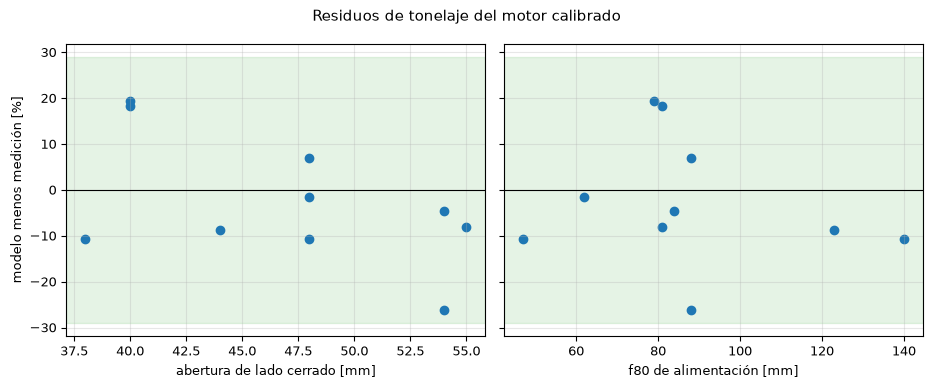

In [5]:
# Grafique los residuos de tonelaje contra la abertura y contra el f80 de alimentación, con la banda de 29 %
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
for ax, x, name in ((left, css, "abertura de lado cerrado [mm]"), (right, f80, "f80 de alimentación [mm]")):
    ax.axhspan(-29, 29, color="tab:green", alpha=0.12)
    ax.axhline(0, color="k", lw=0.8)
    ax.scatter(x, residual)
    ax.set_xlabel(name)
left.set_ylabel("modelo menos medición [%]")
fig.suptitle("Residuos de tonelaje del motor calibrado")
fig.tight_layout()
plt.show()

Ambos paneles quedan dentro de la banda verde, de modo que el motor pasa el filtro de expectativas de tonelaje en cada muestreo. Ningún panel muestra una tendencia clara: los residuos no crecen con la abertura, y frente al f80 tampoco se ordenan, pues la matriz de correlación de arriba da -0,086 entre el tonelaje medido y el f80, cerca de cero, frente a 0,815 entre el tonelaje medido y la abertura. El tonelaje modelado correlaciona con el medido en ese mismo 0,815 solo porque es función de la abertura. Lo que queda es dispersión que ninguna variable explica. Los dos paneles juntos dicen que el modelo captura lo que aporta la abertura y que el resto de la variación de la planta está fuera de las entradas del modelo.

**Paso 3, la potencia.** La potencia medida es la lectura de kW de la propia planta. El motor la informa en dos formas: el consumo de Bond del notebook 02 del tema 04, con el índice de trabajo de la mezcla de 9 kWh/t, y la forma calibrada del artículo, $P_c = 1{,}30\,P_d + 110$ kW, con el consumo de Bond del motor en lugar del $P_d$ específico por tamaño del artículo (Rocha et al., 2024; Bond, 1952; https://onemine.org/documents/the-third-theory-of-comminution). La celda calcula ambas para los diez muestreos, las lista por abertura junto a la medición, e imprime sus errores y su correlación con la potencia medida.

In [6]:
# Potencia de Bond pura y forma calibrada para los diez muestreos, listadas por abertura junto a la potencia medida
bare = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs])
calibrated = np.array([calibrated_power(v) for v in bare])
print("abertura [mm]  medida [kW]  consumo de Bond [kW]  1,30 Pd + 110 [kW]")
for i in np.argsort(css):
    print(f"{css[i]:12.0f} {measured_kw[i]:14.0f} {bare[i]:15.1f} {calibrated[i]:19.1f}")
print("error absoluto medio, Bond puro:", round(loo.mape(measured_kw, bare), 2), "% | forma calibrada:", end=" ")
print(round(loo.mape(measured_kw, calibrated), 2), "%")
print("correlación con la potencia medida, Bond puro:", np.corrcoef(bare, measured_kw)[0, 1].round(3), end=" ")
print("| abertura:", np.corrcoef(css, measured_kw)[0, 1].round(3))

abertura [mm]  medida [kW]  consumo de Bond [kW]  1,30 Pd + 110 [kW]
          38            306           196.1               365.0
          40            355           222.5               399.3
          40            350           221.6               398.0
          44            325           212.7               386.6
          48            262           224.9               402.3
          48            325           234.8               415.2
          48            349           225.7               403.4
          54            209           229.5               408.3
          54            212           233.7               413.8
          55            187           237.5               418.7
error absoluto medio, Bond puro: 26.88 % | forma calibrada: 47.58 %
correlación con la potencia medida, Bond puro: -0.453 | abertura: -0.818


La figura grafica la potencia medida y las dos modeladas contra la abertura.

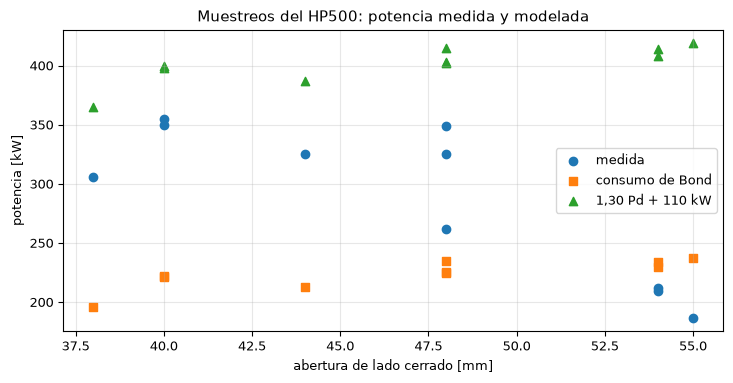

In [7]:
# Grafique la potencia medida y las dos modeladas contra la abertura
fig, ax = plt.subplots()
ax.scatter(css, measured_kw, label="medida", zorder=3)
ax.scatter(css, bare, marker="s", label="consumo de Bond")
ax.scatter(css, calibrated, marker="^", label="1,30 Pd + 110 kW")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("potencia [kW]")
ax.set_title("Muestreos del HP500: potencia medida y modelada")
ax.legend()
fig.tight_layout()
plt.show()

La figura muestra el resultado negativo directamente. La potencia medida baja al abrir la abertura, de 355 kW con 40 mm a 187 kW con 55 mm (la tabla de arriba); las dos potencias modeladas se mantienen planas en una banda angosta, de 196 a 238 kW para el consumo de Bond y de 365 a 419 kW para la forma calibrada, y la forma calibrada queda sobre cada punto medido. Un consumo de Bond plano no puede seguir una cantidad que se mueve con la abertura en un factor de dos: cerrar la abertura hace un producto más fino y sube los kWh por tonelada, mientras el menor tonelaje en toneladas lo cancela en el consumo de Bond, una cancelación que la potencia de la planta no muestra. El resultado no se esconde: las constantes de la forma del artículo pertenecen a la potencia específica por tamaño del propio artículo, no al consumo clásico de Bond usado aquí.

**Paso 4, qué cambia la calibración.** La vía calibrada reemplaza la clasificación sintética, el quiebre y la base de capacidad por el ajuste del artículo. La celda ejecuta cada muestreo dos veces, con la vía calibrada y con la sintética en el mismo punto de operación, imprime el promedio de los tres resultados sobre los diez muestreos para cada una, y lista la potencia de cada vía muestreo por muestreo.

In [8]:
# Ejecute cada muestreo también en la vía sintética y compare los resultados medios de las dos vías
synthetic = [evaluate(replace(operating_from_survey(s.css_mm, s.f80_mm), calibrated=False)) for s in surveys]
for name, field in (("P80 [mm]", "p80"), ("tonelaje [t/h]", "throughput_tph"), ("potencia [kW]", "power_kw")):
    cal_mean = np.mean([getattr(r, field) for r in runs])
    syn_mean = np.mean([getattr(r, field) for r in synthetic])
    print(f"{name:18s} calibrada {cal_mean:7.1f}   sintética {syn_mean:7.1f}")
print("potencia sintética por muestreo [kW]:", np.round([r.power_kw for r in synthetic], 0))
print("potencia calibrada por muestreo [kW]:", np.round([r.power_kw for r in runs], 0))

P80 [mm]           calibrada    29.7   sintética    36.0
tonelaje [t/h]     calibrada  1088.0   sintética   874.4
potencia [kW]      calibrada   401.1   sintética   133.7
potencia sintética por muestreo [kW]: [130. 126.  76. 140. 104. 140. 188. 170. 142. 121.]
potencia calibrada por muestreo [kW]: [408. 414. 402. 403. 415. 399. 365. 387. 398. 419.]


La calibración mueve el tonelaje en cerca de un cuarto, de una media de 874 a una media de 1088 t/h que queda cerca de la de la planta, y el P80 medio en varios milímetros. Mueve la potencia en un factor de tres, de una media sintética de 134 kW a una media calibrada de 401 kW, y ese es el movimiento que aleja al modelo de los 187 a 355 kW medidos. Las líneas por muestreo dicen dónde cae el desfase de 110 kW de la forma: suma los mismos 110 kW a cada muestreo, una cantidad mayor que toda la potencia de la vía sintética en dos muestreos (76 y 104 kW) y comparable con la de los otros ocho (de 121 a 188 kW), así que no es una corrección pequeña de un consumo de Bond. La calibración se ajustó al tamaño y a la capacidad, y la forma de potencia se trasplantó desde la potencia específica por tamaño del artículo a un consumo clásico de Bond al que nunca se ajustó.

**Paso 5, la energía específica.** Dividir la potencia por las toneladas da la energía por tonelada, la cantidad que optimiza una planta. El valor medido es la potencia sobre el flujo de alimentación medido, y el del modelo es la energía de Bond del oráculo para el F80 y el P80 del propio motor. La figura grafica ambas contra la abertura, y las últimas líneas imprimen los valores en los dos extremos del rango de abertura.

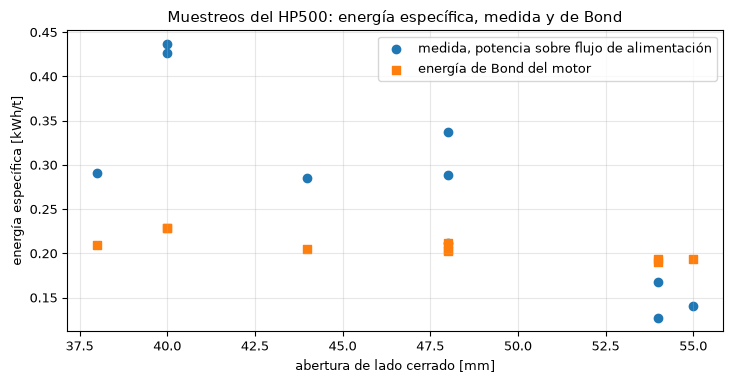

medida con 38 a 40 mm [kWh/t]: [0.437 0.291 0.427]
medida con 54 a 55 mm [kWh/t]: [0.128 0.167 0.14 ]
rango de la energía de Bond [kWh/t]: 0.19 0.229


In [9]:
# Energía específica medida frente a la energía de Bond del motor, por muestreo, contra la abertura
measured_kwh_t = measured_kw / measured_q
bond_kwh_t = np.array([bond_energy_kwh_t(r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs])
fig, ax = plt.subplots()
ax.scatter(css, measured_kwh_t, label="medida, potencia sobre flujo de alimentación")
ax.scatter(css, bond_kwh_t, marker="s", label="energía de Bond del motor")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("energía específica [kWh/t]")
ax.set_title("Muestreos del HP500: energía específica, medida y de Bond")
ax.legend()
fig.tight_layout()
plt.show()
print("medida con 38 a 40 mm [kWh/t]:", measured_kwh_t[css <= 40].round(3))
print("medida con 54 a 55 mm [kWh/t]:", measured_kwh_t[css >= 54].round(3))
print("rango de la energía de Bond [kWh/t]:", bond_kwh_t.min().round(3), bond_kwh_t.max().round(3))

La energía medida por tonelada se más que triplica al cerrar la abertura de 55 a 40 mm, de 0,13 a 0,17 kWh/t con 54 a 55 mm a 0,43 a 0,44 kWh/t con 40 mm (el muestreo 7, con 38 mm, es la excepción con 0,29), como corresponde a que un producto más fino pide más energía por tonelada; la energía de Bond del motor se mueve solo de 0,19 a 0,23 kWh/t. La energía de la planta es mucho más sensible a la abertura que la del modelo, que es el mismo hallazgo de la figura de potencia pero en las unidades que usa una planta. La razón de tamaños de Bond no produce un cambio de tres veces con un cambio de 15 mm de la abertura, de modo que la pieza que falta está en la ley de energía, no en la calibración de los tamaños.

## Resultados

**Respuesta:** el motor reproduce el tonelaje de la planta y no reproduce su potencia. Los diez muestreos pasan el filtro de expectativas: tonelaje a menos de 29 por ciento, P80 entre 0,35 y 1,1 veces la abertura, razón de reducción entre 1,8 y 4. Los residuos de tonelaje tienen una media de -2,6 por ciento, ninguna tendencia organizada frente a la abertura ni al f80, y un error absoluto medio de 11,55 por ciento. La potencia no: los kW medidos bajan de 355 a 187 al abrir la abertura, el consumo de Bond se mueve solo entre 196 y 238 kW y tiene una correlación negativa de -0,453 con la medición, y la forma calibrada, con 47,58 por ciento de error absoluto medio, es la peor de las dos formas que ofrece el motor frente a un Bond puro de 26,88 por ciento.

La primera figura muestra lo que el modelo deja sin explicar en el tonelaje, la segunda la potencia fallando a la planta. Un validador concluiría que el tonelaje es un éxito calibrado y parcial y la potencia un negativo honesto, que el producto informa y no esconde, que el P80 solo puede juzgarse con la relación del chancador alimentado a cámara llena porque el artículo no entrega una tabla de él, y que todos estos números son dentro de la muestra, de modo que ninguno dice aún cómo se comporta el motor con un muestreo al que no se ajustó.

## Resumen

Con datos reales el tonelaje del motor pasa el filtro y sigue la abertura, su potencia no sigue a la planta y el propio informe del producto lo dice, y cada número de este notebook es dentro de la muestra. El protocolo del estado del arte del artículo fuente, el ajuste dentro de la muestra, se ejecuta en el tema 06, notebook 03, donde luego se retienen los muestreos.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193